# P1: anomaly detection benchmark on MVTec AD

PatchCore and PaDiM, each run with two backbones (Wide-ResNet50 and ResNet18), on all 15 MVTec AD categories.
This is a 2x2 design (method x backbone), so the notebook can separate how much of the performance gap comes from the **method** and how much from the **backbone**.

**How to use:** run the cells top to bottom. The notebook only reads `metrics/mvtec_metrics.csv`; it never trains anything. To refresh after new runs, rerun the whole notebook (the prose findings at the end are written for the 17 Oct 2026 run and should be rechecked against the tables).

**Metric notes**
- AUROC needs no threshold, so it is the headline metric. F1 depends on a threshold that anomalib sets automatically, so treat it with caution.
- Image AUROC measures whether a defective image is ranked above a normal one. Pixel AUROC measures how well the anomaly map highlights the defect.
- One seed per run, so differences below about 0.01 are not meaningful.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

CANDIDATES = [
    Path(r"D:\PORTFOLIO_2026\P1_defect_detection\metrics\mvtec_metrics.csv"),
    Path.cwd().parent / "metrics" / "mvtec_metrics.csv",
    Path.cwd() / "mvtec_metrics.csv",
]
METRICS_CSV = next((p for p in CANDIDATES if p.exists()), None)
if METRICS_CSV is None:
    raise FileNotFoundError("mvtec_metrics.csv not found. Tried:\n" + "\n".join(map(str, CANDIDATES)))

FIG_DIR = METRICS_CSV.parent.parent / "figures"
FIG_DIR.mkdir(exist_ok=True)
print("Reading:", METRICS_CSV)
print("Figures are saved to:", FIG_DIR)

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
METHOD_COLOR = {"PatchCore": "#2a78d6", "PaDiM": "#eb6834"}
EFFECT_COLOR = {"method": "#6250d6", "backbone": "#008300"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": ["Segoe UI", "Arial", "DejaVu Sans"], "font.size": 10.5,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": MUTED, "ytick.color": INK2,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": False, "figure.dpi": 110,
})

Reading: /tmp/claude-0/-home-claude/4b5b5f1e-743e-5689-8bdb-9afb8b86054f/scratchpad/P1/metrics/mvtec_metrics.csv
Figures are saved to: /tmp/claude-0/-home-claude/4b5b5f1e-743e-5689-8bdb-9afb8b86054f/scratchpad/P1/figures


## 0. Load and check the data

In [2]:
VARIANTS = {                       # model name in the CSV -> (method, backbone)
    "patchcore":     ("PatchCore", "WRN50"),
    "patchcore_r18": ("PatchCore", "R18"),
    "padim":         ("PaDiM",     "R18"),
    "padim_wrn50":   ("PaDiM",     "WRN50"),
}
VARIANT_OF = {v: k for k, v in VARIANTS.items()}
TEXTURES = {"carpet", "grid", "leather", "tile", "wood"}

raw = pd.read_csv(METRICS_CSV)
unknown = set(raw["model"]) - set(VARIANTS)
assert not unknown, f"Unexpected model names in the CSV: {unknown}"
assert not raw.duplicated(["model", "category"]).any(), "Duplicate (model, category) rows in the CSV"
counts = raw.groupby("model").size()
assert (counts == 15).all() and len(counts) == 4, f"Expected 4 variants x 15 categories, got:\n{counts}"

df = raw.copy()
df["method"] = df["model"].map(lambda m: VARIANTS[m][0])
df["backbone"] = df["model"].map(lambda m: VARIANTS[m][1])
df["group"] = np.where(df["category"].isin(TEXTURES), "texture", "object")
print(f"{len(df)} rows: 4 variants x 15 categories, no duplicates")

def wide(metric):
    # one row per category, one column per model name
    return df.pivot_table(index="category", columns="model", values=metric)

img, pix = wide("image_AUROC"), wide("pixel_AUROC")

60 rows: 4 variants x 15 categories, no duplicates


## 1. The 2x2 result

Mean over the 15 categories. Rows are methods, columns are backbones.
PaDiM with Wide-ResNet50 uses 100 features (not the paper's 550) because the full setting does not fit in 8 GB of GPU memory.

In [3]:
def two_by_two(metric):
    t = df.pivot_table(index="method", columns="backbone", values=metric)
    return t.loc[["PatchCore", "PaDiM"], ["WRN50", "R18"]].round(3)

for metric, label in [("image_AUROC", "Image AUROC"), ("pixel_AUROC", "Pixel AUROC"), ("pixel_F1Score", "Pixel F1")]:
    print(label)
    display(two_by_two(metric))

Image AUROC


backbone,WRN50,R18
method,,
PatchCore,0.982,0.969
PaDiM,0.908,0.888


Pixel AUROC


backbone,WRN50,R18
method,,
PatchCore,0.980,0.975
PaDiM,0.962,0.960


Pixel F1


backbone,WRN50,R18
method,,
PatchCore,0.582,0.559
PaDiM,0.468,0.466


## 2. Method effect vs backbone effect

All values are differences in image AUROC. A positive method effect means PatchCore beats PaDiM.

In [4]:
effects = pd.DataFrame({
    "method_gap_WRN50":        img["patchcore"]     - img["padim_wrn50"],
    "method_gap_R18":          img["patchcore_r18"] - img["padim"],
    "backbone_gain_PatchCore": img["patchcore"]     - img["patchcore_r18"],
    "backbone_gain_PaDiM":     img["padim_wrn50"]   - img["padim"],
})
ORDER = effects.sort_values("method_gap_WRN50", ascending=False).index.tolist()

display(effects.loc[ORDER].round(3))

print("Mean over categories:")
display(effects.mean().round(3).to_frame("mean").T)

print(f"PatchCore beats PaDiM on image AUROC: {(effects.method_gap_WRN50 > 0).sum()}/15 at WRN50, "
      f"{(effects.method_gap_R18 > 0).sum()}/15 at R18")
print(f"Pixel AUROC, PatchCore beats PaDiM: {(pix['patchcore'] > pix['padim_wrn50']).sum()}/15 at WRN50, "
      f"{(pix['patchcore_r18'] > pix['padim']).sum()}/15 at R18")
print(f"Bigger backbone helps PaDiM on {(effects.backbone_gain_PaDiM > 0).sum()}/15 categories, "
      f"hurts on {(effects.backbone_gain_PaDiM < 0).sum()}/15")

,method_gap_WRN50,method_gap_R18,backbone_gain_PatchCore,backbone_gain_PaDiM
category,,,,
screw,0.271,0.201,0.001,-0.069
cable,0.170,0.132,0.018,-0.020
capsule,0.136,0.082,0.010,-0.044
pill,0.123,0.081,0.040,-0.002
hazelnut,0.111,0.284,0.000,0.173
grid,0.067,0.132,0.034,0.099
metal_nut,0.066,0.041,0.005,-0.020
zipper,0.063,0.020,0.032,-0.011
transistor,0.048,0.046,0.006,0.004


Mean over categories:


,method_gap_WRN50,method_gap_R18,backbone_gain_PatchCore,backbone_gain_PaDiM
mean,0.074,0.081,0.013,0.02


PatchCore beats PaDiM on image AUROC: 14/15 at WRN50, 13/15 at R18
Pixel AUROC, PatchCore beats PaDiM: 15/15 at WRN50, 12/15 at R18
Bigger backbone helps PaDiM on 7/15 categories, hurts on 8/15


## 3. Every category, all four variants

Color shows the method, fill shows the backbone (filled = Wide-ResNet50, hollow = ResNet18). The line joins the two backbones of the same method, so its length is the backbone effect. Categories are sorted by the method gap at Wide-ResNet50, largest at the top.

findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


...

findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


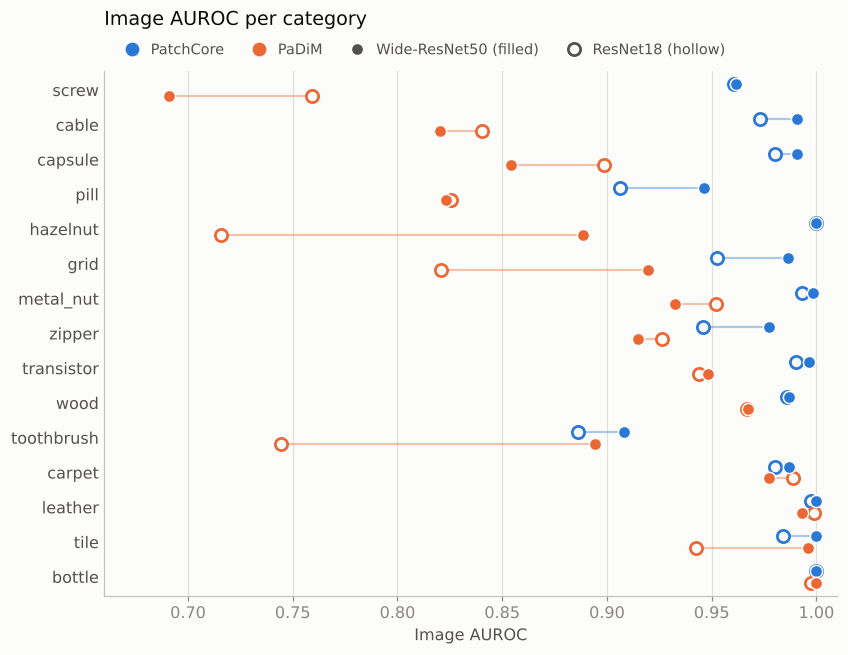

In [5]:
def legend_handles():
    h = [Line2D([], [], marker="o", ls="", ms=8, mfc=c, mec=c, label=m) for m, c in METHOD_COLOR.items()]
    h += [Line2D([], [], marker="o", ls="", ms=8, mfc=INK2, mec=SURFACE, label="Wide-ResNet50 (filled)"),
          Line2D([], [], marker="o", ls="", ms=8, mfc=SURFACE, mec=INK2, mew=1.8, label="ResNet18 (hollow)")]
    return h

def dot_panel(ax, table, order, xlim, xlabel):
    # table: rows = labels, columns = model names
    ys = np.arange(len(order))[::-1].astype(float)
    off = {"PatchCore": 0.17, "PaDiM": -0.17}
    ax.set_axisbelow(True)
    ax.xaxis.grid(True, color=GRID, lw=0.8)
    for method, color in METHOD_COLOR.items():
        r18 = table.loc[order, VARIANT_OF[(method, "R18")]].to_numpy()
        wrn = table.loc[order, VARIANT_OF[(method, "WRN50")]].to_numpy()
        for yy, lo, hi in zip(ys + off[method], r18, wrn):
            ax.plot([lo, hi], [yy, yy], color=color, lw=1.4, alpha=0.4, solid_capstyle="round", zorder=2)
        ax.scatter(r18, ys + off[method], s=64, facecolor=SURFACE, edgecolor=color, linewidth=1.8, zorder=3)
        ax.scatter(wrn, ys + off[method], s=64, facecolor=color, edgecolor=SURFACE, linewidth=1.0, zorder=4)
    ax.set_yticks(ys)
    ax.set_yticklabels(order)
    ax.set_xlim(*xlim)
    ax.set_ylim(-0.55, len(order) - 0.45)
    ax.set_xlabel(xlabel)
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", length=3)

def category_figure(metric, xlim, fname, title):
    fig, ax = plt.subplots(figsize=(8.6, 6.2))
    dot_panel(ax, wide(metric), ORDER, xlim, {"image_AUROC": "Image AUROC", "pixel_AUROC": "Pixel AUROC"}[metric])
    ax.legend(handles=legend_handles(), loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4, frameon=False,
              fontsize=9.5, labelcolor=INK2, handletextpad=0.3, columnspacing=1.4)
    ax.set_title(title, loc="left", pad=30, fontsize=12.5, color=INK, weight="medium")
    fig.savefig(FIG_DIR / fname, dpi=200, bbox_inches="tight")
    plt.show()

category_figure("image_AUROC", (0.66, 1.01), "image_auroc_by_category.png", "Image AUROC per category")

findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


...

findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


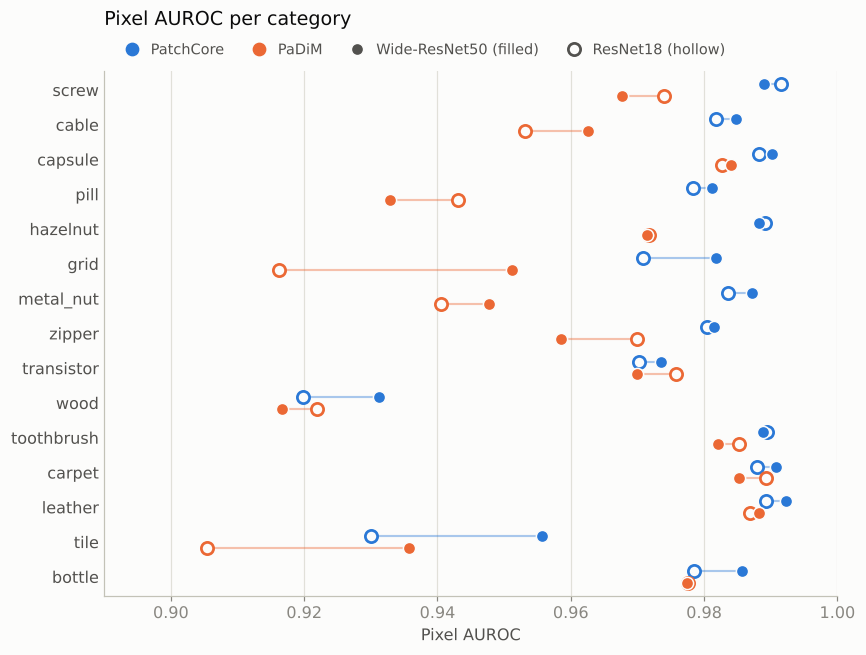

In [6]:
category_figure("pixel_AUROC", (0.89, 1.0), "pixel_auroc_by_category.png", "Pixel AUROC per category")

## 4. How much is the method, how much is the backbone?

For each category, the purple bar is the gain from switching PaDiM to PatchCore (both on Wide-ResNet50). The green bar is the gain PaDiM gets from the bigger backbone. Labels are shown for effects of 0.10 or more in size.

findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


...

findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


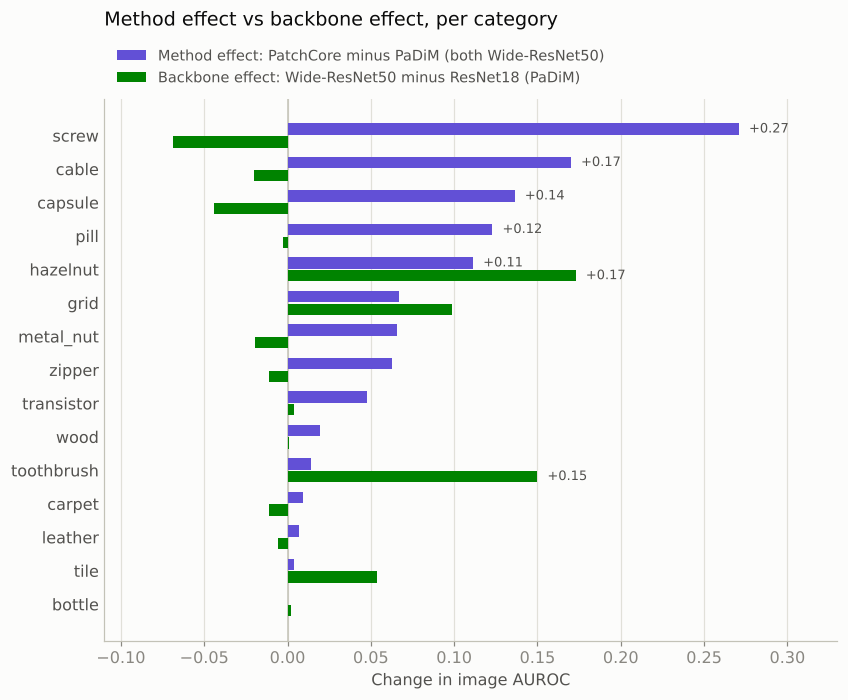

In [7]:
fig, ax = plt.subplots(figsize=(8.6, 6.4))
ys = np.arange(len(ORDER))[::-1].astype(float)
h, gap = 0.34, 0.02
method = effects.loc[ORDER, "method_gap_WRN50"].to_numpy()
backbone = effects.loc[ORDER, "backbone_gain_PaDiM"].to_numpy()

ax.set_axisbelow(True)
ax.xaxis.grid(True, color=GRID, lw=0.8)
ax.axvline(0, color=AXIS, lw=1.0, zorder=1)
ax.barh(ys + h / 2 + gap, method, height=h, color=EFFECT_COLOR["method"],
        label="Method effect: PatchCore minus PaDiM (both Wide-ResNet50)")
ax.barh(ys - h / 2 - gap, backbone, height=h, color=EFFECT_COLOR["backbone"],
        label="Backbone effect: Wide-ResNet50 minus ResNet18 (PaDiM)")

for yy, v in list(zip(ys + h / 2 + gap, method)) + list(zip(ys - h / 2 - gap, backbone)):
    if abs(v) >= 0.10:
        ax.text(v + (0.006 if v > 0 else -0.006), yy, f"{v:+.2f}", va="center",
                ha="left" if v > 0 else "right", fontsize=8.5, color=INK2)

ax.set_yticks(ys)
ax.set_yticklabels(ORDER)
ax.set_xlim(-0.11, 0.33)
ax.set_xlabel("Change in image AUROC")
ax.tick_params(axis="y", length=0)
ax.tick_params(axis="x", length=3)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=1, frameon=False, fontsize=9.5, labelcolor=INK2)
ax.set_title("Method effect vs backbone effect, per category", loc="left", pad=48, fontsize=12.5, color=INK, weight="medium")
fig.savefig(FIG_DIR / "method_vs_backbone_effect.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Textures vs objects

Same encoding as section 3, averaged over the 5 texture categories (carpet, grid, leather, tile, wood) and the 10 object categories.

findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


...

findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


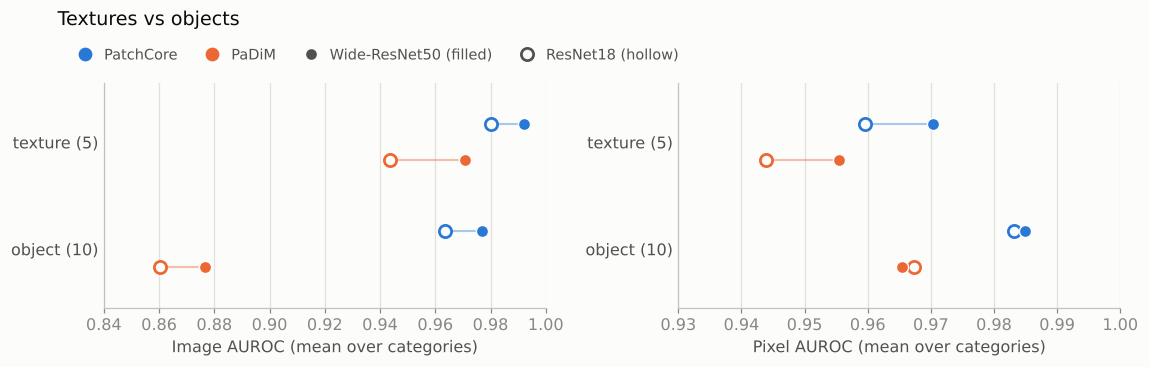

In [8]:
def grouped(metric):
    t = df.pivot_table(index="group", columns="model", values=metric)
    return t.rename(index={"texture": "texture (5)", "object": "object (10)"})

rows = ["texture (5)", "object (10)"]
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
fig.subplots_adjust(left=0.1, right=0.98, top=0.80, bottom=0.2, wspace=0.3)
dot_panel(axes[0], grouped("image_AUROC"), rows, (0.84, 1.0), "Image AUROC (mean over categories)")
dot_panel(axes[1], grouped("pixel_AUROC"), rows, (0.93, 1.0), "Pixel AUROC (mean over categories)")
fig.legend(handles=legend_handles(), loc="lower left", bbox_to_anchor=(0.06, 0.82), ncol=4, frameon=False,
           fontsize=9.5, labelcolor=INK2, handletextpad=0.3, columnspacing=1.4)
fig.text(0.06, 0.995, "Textures vs objects", ha="left", va="top", fontsize=12.5, color=INK, weight="medium")
fig.savefig(FIG_DIR / "texture_vs_object.png", dpi=200, bbox_inches="tight")
plt.show()

## 6. Which defect types are missed? (optional, needs `failure_analysis.py` output)

This section reads `metrics/defect_type_detection.csv`, written by `src/failure_analysis.py`. It only covers the categories you ran that script on, and compares PatchCore with PaDiM, both on Wide-ResNet50.

**Detection rate** here is the share of defective test images that score above the 95th percentile of the *normal* test images of the same category. That fixes the false-alarm rate at about 5%, so the two methods are compared at the same operating point. With 10 to 25 images per defect type, a rate moves by 4 to 10 points per image, so only large differences are meaningful.

In [9]:
DT_CSV = METRICS_CSV.parent / "defect_type_detection.csv"
if not DT_CSV.exists():
    print("defect_type_detection.csv not found. Run src/failure_analysis.py first; skipping this section.")
    dtd = None
else:
    dtd = pd.read_csv(DT_CSV)
    dtd["defect_type"] = dtd["defect_type"].str.replace("ALL DEFECTS", "ALL", regex=False)
    overall = dtd[dtd["defect_type"] == "ALL"].set_index("category")[["n_images", "tpr_patchcore", "tpr_padim_wrn50"]]
    overall.columns = ["defect images", "PatchCore", "PaDiM (WRN50)"]
    print(f"Categories analysed: {', '.join(overall.index)}")
    print("Detection rate at about 5% false alarms, all defect types pooled")
    display(overall.style.format({"PatchCore": "{:.1%}", "PaDiM (WRN50)": "{:.1%}"}))

Categories analysed: screw, cable, capsule, hazelnut
Detection rate at about 5% false alarms, all defect types pooled


,defect images,PatchCore,PaDiM (WRN50)
category,,,
screw,119,82.4%,6.7%
cable,92,97.8%,39.1%
capsule,109,96.3%,41.3%
hazelnut,70,100.0%,64.3%


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


...

findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


findfont: Font family 'Segoe UI' not found.


findfont: Font family 'Arial' not found.


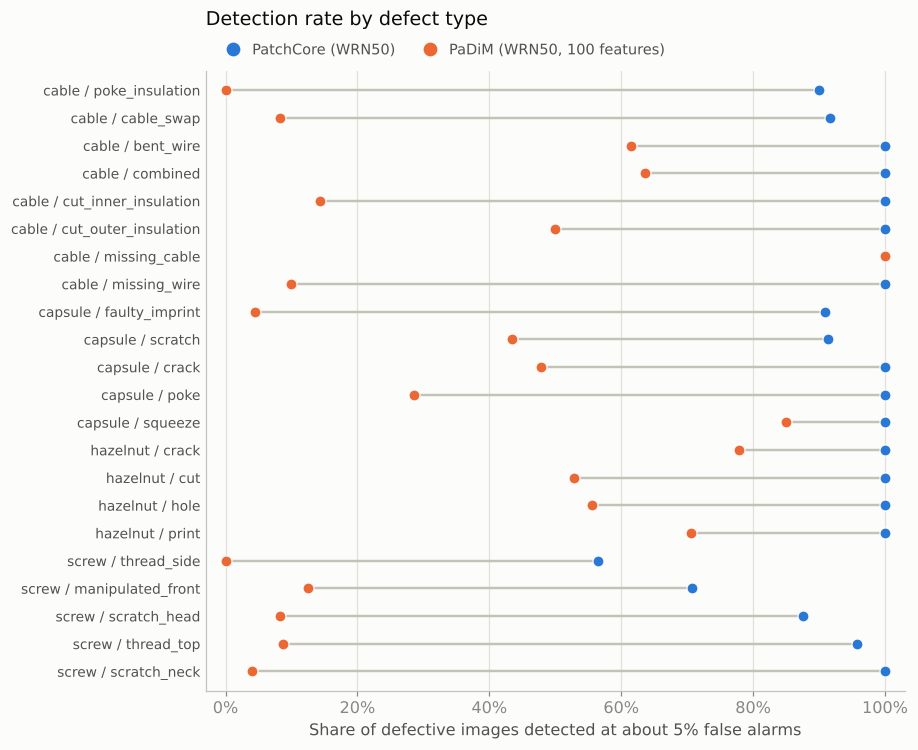

PatchCore's five weakest defect types (among the analysed categories)


defect type,images,PatchCore,PaDiM (WRN50)
screw / thread_side,23,56.5%,0.0%
screw / manipulated_front,24,70.8%,12.5%
screw / scratch_head,24,87.5%,8.3%
cable / poke_insulation,10,90.0%,0.0%
capsule / faulty_imprint,22,90.9%,4.5%


In [10]:
if dtd is not None:
    types = dtd[dtd["defect_type"] != "ALL"].copy()
    types["label"] = types["category"] + " / " + types["defect_type"]
    types = types.sort_values(["category", "tpr_patchcore"], ascending=[True, True]).reset_index(drop=True)
    n = len(types)
    ys = np.arange(n)[::-1].astype(float)

    fig, ax = plt.subplots(figsize=(8.2, 0.26 * n + 1.6))
    ax.set_axisbelow(True)
    ax.xaxis.grid(True, color=GRID, lw=0.8)
    ax.hlines(ys, types["tpr_padim_wrn50"], types["tpr_patchcore"], color=AXIS, lw=1.6, zorder=2)
    ax.scatter(types["tpr_patchcore"], ys, s=52, color=METHOD_COLOR["PatchCore"], edgecolor=SURFACE, linewidth=0.8, zorder=4)
    ax.scatter(types["tpr_padim_wrn50"], ys, s=52, color=METHOD_COLOR["PaDiM"], edgecolor=SURFACE, linewidth=0.8, zorder=4)
    ax.set_yticks(ys)
    ax.set_yticklabels(types["label"], fontsize=9)
    ax.set_xlim(-0.03, 1.03)
    ax.set_ylim(-0.7, n - 0.3)
    ax.set_xticks(np.linspace(0, 1, 6))
    ax.set_xticklabels([f"{int(v * 100)}%" for v in np.linspace(0, 1, 6)])
    ax.set_xlabel("Share of defective images detected at about 5% false alarms")
    ax.tick_params(axis="y", length=0)
    ax.tick_params(axis="x", length=3)
    handles = [Line2D([], [], marker="o", ls="", ms=8, mfc=c, mec=c, label=m) for m, c in
               [("PatchCore (WRN50)", METHOD_COLOR["PatchCore"]), ("PaDiM (WRN50, 100 features)", METHOD_COLOR["PaDiM"])]]
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False,
              fontsize=9.5, labelcolor=INK2, handletextpad=0.3, columnspacing=1.4)
    ax.set_title("Detection rate by defect type", loc="left", pad=30, fontsize=12.5, color=INK, weight="medium")
    fig.savefig(FIG_DIR / "defect_type_detection.png", dpi=200, bbox_inches="tight")
    plt.show()

    weakest = types.nsmallest(5, "tpr_patchcore")[["label", "n_images", "tpr_patchcore", "tpr_padim_wrn50"]]
    weakest.columns = ["defect type", "images", "PatchCore", "PaDiM (WRN50)"]
    print("PatchCore's five weakest defect types (among the analysed categories)")
    display(weakest.style.hide(axis="index").format({"PatchCore": "{:.1%}", "PaDiM (WRN50)": "{:.1%}"}))

## 7. What does each variant cost? (optional, needs `cost_benchmark.py` output)

This section reads `metrics/cost_table.csv`, written by `src/cost_benchmark.py`. Latency is the model's forward pass on one image (median of 50 runs, random input, GPU), so it excludes image loading and resizing. Throughput uses batches of 16. Peak memory is GPU memory during one single-image pass. Checkpoint size is the file you would have to ship. Values are medians over the categories measured.

In [11]:
COST_CSV = METRICS_CSV.parent / "cost_table.csv"
if not COST_CSV.exists():
    print("cost_table.csv not found. Run src/cost_benchmark.py first; skipping this section.")
    cost = None
else:
    raw_cost = pd.read_csv(COST_CSV)
    print(f"Categories measured: {', '.join(sorted(raw_cost['category'].unique()))}")
    cost = raw_cost.groupby("variant")[["ckpt_mb", "latency_ms_bs1", "throughput_img_s_bs16", "peak_vram_mb"]].median()
    cost["image_AUROC"] = df.groupby("model")["image_AUROC"].mean()
    cost["pixel_AUROC"] = df.groupby("model")["pixel_AUROC"].mean()
    cost.index = [f"{VARIANTS[v][0]} ({VARIANTS[v][1]})" for v in cost.index]
    cost = cost.sort_values("image_AUROC", ascending=False)
    shown = cost.rename(columns={
        "ckpt_mb": "checkpoint (MB)", "latency_ms_bs1": "latency (ms/image)",
        "throughput_img_s_bs16": "throughput (images/s)", "peak_vram_mb": "peak GPU memory (MB)",
        "image_AUROC": "mean image AUROC", "pixel_AUROC": "mean pixel AUROC"})
    display(shown.style.format({"checkpoint (MB)": "{:.0f}", "latency (ms/image)": "{:.1f}",
                                "throughput (images/s)": "{:.0f}", "peak GPU memory (MB)": "{:.0f}",
                                "mean image AUROC": "{:.3f}", "mean pixel AUROC": "{:.3f}"}))

cost_table.csv not found. Run src/cost_benchmark.py first; skipping this section.


In [12]:
if cost is not None:
    fig, ax = plt.subplots(figsize=(7.2, 4.2))
    ax.set_axisbelow(True)
    ax.grid(True, color=GRID, lw=0.8)
    for name, row in cost.iterrows():
        method = name.split(" ")[0]
        filled = "WRN50" in name
        ax.scatter(row["latency_ms_bs1"], row["image_AUROC"], s=110,
                   facecolor=METHOD_COLOR[method] if filled else SURFACE,
                   edgecolor=METHOD_COLOR[method], linewidth=1.8, zorder=3)
        ax.annotate(name, (row["latency_ms_bs1"], row["image_AUROC"]), xytext=(8, 6),
                    textcoords="offset points", fontsize=9, color=INK2)
    ax.set_xlabel("Latency per image (ms, batch of 1, lower is better)")
    ax.set_ylabel("Mean image AUROC (higher is better)")
    ax.margins(x=0.25, y=0.15)
    ax.tick_params(length=3)
    ax.set_title("Accuracy against speed", loc="left", pad=10, fontsize=12.5, color=INK, weight="medium")
    fig.savefig(FIG_DIR / "accuracy_vs_latency.png", dpi=200, bbox_inches="tight")
    plt.show()

## 8. Export a README-ready table

In [13]:
def md_table(frame, title):
    cols = [title] + list(frame.columns)
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in frame.iterrows():
        lines.append("| " + " | ".join([str(idx)] + [f"{v:.3f}" for v in row]) + " |")
    return "\n".join(lines)

readme_tables = "\n\n".join([
    "Mean image AUROC (15 MVTec AD categories)\n\n" + md_table(two_by_two("image_AUROC"), "Method"),
    "Mean pixel AUROC (15 MVTec AD categories)\n\n" + md_table(two_by_two("pixel_AUROC"), "Method"),
])
(FIG_DIR / "summary_tables.md").write_text(readme_tables + "\n", encoding="utf-8")
print(readme_tables)

Mean image AUROC (15 MVTec AD categories)

| Method | WRN50 | R18 |
|---|---|---|
| PatchCore | 0.982 | 0.969 |
| PaDiM | 0.908 | 0.888 |

Mean pixel AUROC (15 MVTec AD categories)

| Method | WRN50 | R18 |
|---|---|---|
| PatchCore | 0.980 | 0.975 |
| PaDiM | 0.962 | 0.960 |


## 9. Findings (written for the 17 Oct 2026 run)

1. **The method matters far more than the backbone.** Replacing PaDiM with PatchCore adds about 0.07 to 0.08 image AUROC at either backbone. Replacing ResNet18 with Wide-ResNet50 adds only about 0.01 (PatchCore) to 0.02 (PaDiM).
2. **PatchCore wins almost everywhere.** At Wide-ResNet50 it is ahead on 14 of 15 categories for image AUROC (one tie, `bottle`) and on all 15 for pixel AUROC. At ResNet18 the lead is slightly smaller: 13 of 15 for image AUROC and 12 of 15 for pixel AUROC.
3. **`screw` is a robust PaDiM weakness.** PaDiM stays at about 0.69 image AUROC even with the bigger backbone, 0.27 below PatchCore.
4. **`hazelnut` is mostly a backbone effect for PaDiM.** The bigger backbone lifts it from about 0.72 to 0.89, so most of that gap closes. An earlier guess that random object rotation alone explains the `hazelnut` and `screw` gaps is not supported by the `hazelnut` result.
5. **The backbone effect for PaDiM is mixed.** It helps on 7 of 15 categories and hurts on 8. A possible explanation (not tested) is that keeping 100 of the 1,792 available features discards information that the wider backbone provides.
6. **Textures are harder to localize than objects in all four variants** (lower pixel AUROC), even though textures are as easy or easier to detect at the image level.
7. **At a fixed 5% false-alarm rate PaDiM misses most defects in several categories.** On the 8 categories analysed in section 6, PatchCore (Wide-ResNet50) detects 60% to 100% of defects, and PaDiM (Wide-ResNet50) detects 7% to 78%. PatchCore is ahead on 35 of 39 defect types and tied on 4 (none behind). The weakest PatchCore cases are `screw` `thread_side` (57%), `toothbrush` (60%), `pill` `crack` (65%) and `pill` `color` (68%). Because `toothbrush` has a single defect class and 30 test images, its rate is uncertain.
8. **PatchCore costs about 3x the latency of PaDiM at the same backbone, but the cost is small in absolute terms.** On a single image, median over 7 categories, PatchCore with Wide-ResNet50 takes 15.3 ms and PaDiM with Wide-ResNet50 takes 4.6 ms. Both are fast enough for a production line running at tens of images per second on this GPU. Checkpoints are similar in size (241 MB and 265 MB).
9. **PatchCore with ResNet18 is the best trade-off in this benchmark.** It gives up 0.013 image AUROC against the Wide-ResNet50 version (0.969 against 0.982) and needs 6.8 ms per image and a 46 MB checkpoint, and it is still 0.08 image AUROC above PaDiM with either backbone.

## 10. Caveats

- PaDiM with Wide-ResNet50 used 100 features instead of the paper's 550 (GPU memory limit). Results at 550 may differ.
- One seed per run. Differences below about 0.01 should not be interpreted, and several categories have small test sets, so a single image can move AUROC noticeably.
- All runs used anomalib's default image size and preprocessing for the installed version.
- Section 6 covers 8 of the 15 categories (`screw`, `cable`, `capsule`, `hazelnut`, `pill`, `grid`, `toothbrush`, `transistor`), chosen partly because they were hard, so the detection rates are not an average over the whole benchmark. Some defect types have only 10 to 25 test images.
- Section 7 times only the model's forward pass on random input on one RTX 3070, over 7 categories, with other programs closed. It excludes image loading, resizing and score post-processing, so use the numbers to compare variants, not as deployment speed.
- F1 scores depend on an automatically chosen threshold and are not used for the conclusions above.